# **Introduction**

## **Project Overview**
Fairness in machine learning is critical, especially in high-stakes applications such as credit approval systems. Machine learning models trained on biased datasets can reinforce existing inequalities, such as denying loans to individuals based on sensitive attributes like race, gender, or socio-economic status. This project aims to explore bias mitigation techniques across the machine learning lifecycle using a dataset related to credit approval.

## **Dataset Context**
The dataset used for this project pertains to a credit system that determines loan approval for individuals. The dataset includes various features such as income level, credit score, loan amount, employment history, and sensitive attributes like gender, age.

## **Goal**
The goal is to identify and mitigate biases in the credit approval process to ensure fair treatment across different demographic groups while maintaining model performance.

## **Potential Sources of Bias**
Bias can originate from several sources in this dataset:
1. **Historical Discrimination**:
   - Loan approval rates may historically favor certain groups, such as males or people from specific age ranges.
2. **Representation Bias**:
   - Underrepresentation of certain demographic groups (e.g., women, minorities, or low-income individuals) in the dataset can lead to biased outcomes.
3. **Feature Bias**:
   - Features like "income level" or "employment history" may inherently favor privileged groups if they correlate with sensitive attributes such as race or gender.
4. **Outcome Bias**:
   - Disparities in the approval rates between privileged and unprivileged groups (e.g., males versus females or younger versus older applicants).

## **Privileged and Unprivileged Groups**
In this context, we identify the following:
- **Privileged Group**: Males, younger individuals, or higher-income earners.
- **Unprivileged Group**: Females, older individuals, or lower-income earners.



In [4]:
pip install aif360 numpy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric
from aif360.algorithms.inprocessing import PrejudiceRemover

# Load the German Credit dataset
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
column_names = ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status',
                'employment', 'installment_commitment', 'personal_status', 'other_parties', 'residence_since',
                'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job',
                'num_dependents', 'own_telephone', 'foreign_worker', 'class']

df = pd.read_csv(url, delim_whitespace=True, header=None, names=column_names)

# Preprocess the dataset
df['class'] = df['class'].replace({1: 1, 2: 0})  # Good: 1, Bad: 0

# Separate numeric and categorical columns
numeric_columns = df.select_dtypes(include=[np.number]).columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Handle missing values for numeric columns
numeric_imputer = SimpleImputer(strategy='mean')
df[numeric_columns] = numeric_imputer.fit_transform(df[numeric_columns])

# Encode categorical variables
label_encoders = {}
for col in categorical_columns:
    label_encoders[col] = LabelEncoder()
    df[col] = label_encoders[col].fit_transform(df[col])

# Binarize the age attribute for fairness
df['age'] = np.where(df['age'] >= 25, 1, 0)  # 1: Older (Privileged), 0: Younger (Unprivileged)

# Convert to BinaryLabelDataset
dataset = BinaryLabelDataset(df=df, label_names=['class'], protected_attribute_names=['age'])

# Split the dataset into train and test sets
dataset_train, dataset_test = dataset.split([0.7], shuffle=True)

# Calculate initial fairness metrics
metric_orig_train = ClassificationMetric(dataset_train, dataset_train, 
                                         privileged_groups=[{'age': 1}], 
                                         unprivileged_groups=[{'age': 0}])

print(f"Initial Statistical Parity Difference: {metric_orig_train.statistical_parity_difference():.4f}")
print(f"Initial Equal Opportunity Difference: {metric_orig_train.equal_opportunity_difference():.4f}")

# Apply Prejudice Remover (In-processing)
etas = [0.1, 0.5, 1.0, 2.0, 5.0]
for eta in etas:
    print(f"\nApplying Prejudice Remover with eta={eta}")
    pr = PrejudiceRemover(sensitive_attr='age', eta=eta)
    pr.fit(dataset_train)
    pr_dataset = pr.predict(dataset_test)

    # Calculate fairness metrics after Prejudice Remover
    metric_pr = ClassificationMetric(dataset_test, pr_dataset, 
                                      privileged_groups=[{'age': 1}], 
                                      unprivileged_groups=[{'age': 0}])
    
    stat_parity_diff_pr = metric_pr.statistical_parity_difference()
    equal_opp_diff_pr = metric_pr.equal_opportunity_difference()
    avg_odds_diff_pr = metric_pr.average_odds_difference()

    print(f"Statistical Parity Difference: {stat_parity_diff_pr:.4f}")
    print(f"Equal Opportunity Difference: {equal_opp_diff_pr:.4f}")
    print(f"Average Odds Difference: {avg_odds_diff_pr:.4f}")

# Visualize Transformed Dataset Features 
print("\nExample Transformed Dataset Features:\n", pr_dataset.features[:5])


/var/folders/8f/j9bb2nzs27g8wwq5kb3dhkxm0000gn/T/ipykernel_8977/1493759366.py:17: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, header=None, names=column_names)


Initial Statistical Parity Difference: -0.1457
Initial Equal Opportunity Difference: 0.0000

Applying Prejudice Remover with eta=0.1


/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-le

Statistical Parity Difference: -0.2220
Equal Opportunity Difference: -0.2692
Average Odds Difference: -0.1757

Applying Prejudice Remover with eta=0.5


/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-le

Statistical Parity Difference: -0.2220
Equal Opportunity Difference: -0.2692
Average Odds Difference: -0.1757

Applying Prejudice Remover with eta=1.0


... (2 outputs left out)

/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-le

Statistical Parity Difference: -0.2220
Equal Opportunity Difference: -0.2692
Average Odds Difference: -0.1757

Applying Prejudice Remover with eta=5.0


/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-le

Statistical Parity Difference: -0.2220
Equal Opportunity Difference: -0.2692
Average Odds Difference: -0.1757

Example Transformed Dataset Features:
 [[1.000e+00 1.800e+01 3.000e+00 9.000e+00 2.427e+03 4.000e+00 4.000e+00
  4.000e+00 2.000e+00 0.000e+00 2.000e+00 1.000e+00 1.000e+00 2.000e+00
  1.000e+00 2.000e+00 2.000e+00 1.000e+00 0.000e+00 0.000e+00]
 [1.000e+00 2.600e+01 2.000e+00 1.000e+00 7.966e+03 0.000e+00 1.000e+00
  2.000e+00 2.000e+00 0.000e+00 3.000e+00 2.000e+00 1.000e+00 2.000e+00
  1.000e+00 2.000e+00 2.000e+00 1.000e+00 0.000e+00 0.000e+00]
 [0.000e+00 2.400e+01 2.000e+00 1.000e+00 6.579e+03 0.000e+00 0.000e+00
  4.000e+00 2.000e+00 0.000e+00 2.000e+00 3.000e+00 1.000e+00 2.000e+00
  2.000e+00 1.000e+00 3.000e+00 1.000e+00 1.000e+00 0.000e+00]
 [0.000e+00 1.800e+01 1.000e+00 4.000e+00 1.940e+03 0.000e+00 1.000e+00
  3.000e+00 2.000e+00 1.000e+00 4.000e+00 3.000e+00 1.000e+00 0.000e+00
  2.000e+00 1.000e+00 3.000e+00 1.000e+00 1.000e+00 0.000e+00]
 [3.000e+00 1.200e+01 

In [41]:
%matplotlib inline
# Load all necessary packages
import sys
sys.path.append("../")
import numpy as np
from tqdm import tqdm

from aif360.datasets import BinaryLabelDataset
from aif360.datasets import AdultDataset, GermanDataset, CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.metrics import ClassificationMetric
from aif360.algorithms.preprocessing.reweighing import Reweighing
from aif360.algorithms.preprocessing.optim_preproc_helpers.data_preproc_functions\
        import load_preproc_data_adult, load_preproc_data_german, load_preproc_data_compas
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from common_utils import compute_metrics


In [27]:
## import dataset
dataset_used = "german" # "adult", "german", "compas"
protected_attribute_used = 1 # 1, 2


if dataset_used == "adult":
#     dataset_orig = AdultDataset()
    if protected_attribute_used == 1:
        privileged_groups = [{'sex': 1}]
        unprivileged_groups = [{'sex': 0}]
        dataset_orig = load_preproc_data_adult(['sex'])
    else:
        privileged_groups = [{'race': 1}]
        unprivileged_groups = [{'race': 0}]
        dataset_orig = load_preproc_data_adult(['race'])
    
elif dataset_used == "german":
#     dataset_orig = GermanDataset()
    if protected_attribute_used == 1:
        privileged_groups = [{'sex': 1}]
        unprivileged_groups = [{'sex': 0}]
        dataset_orig = load_preproc_data_german(['sex'])
    else:
        privileged_groups = [{'age': 1}]
        unprivileged_groups = [{'age': 0}]
        dataset_orig = load_preproc_data_german(['age'])
    
elif dataset_used == "compas":
#     dataset_orig = CompasDataset()
    if protected_attribute_used == 1:
        privileged_groups = [{'sex': 1}]
        unprivileged_groups = [{'sex': 0}]
        dataset_orig = load_preproc_data_compas(['sex'])
    else:
        privileged_groups = [{'race': 1}]
        unprivileged_groups = [{'race': 0}]
        dataset_orig = load_preproc_data_compas(['race'])

all_metrics =  ["Statistical parity difference",
                   "Average odds difference",
                   "Equal opportunity difference"]

#random seed for calibrated equal odds prediction
np.random.seed(1)

/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/aif360/algorithms/preprocessing/optim_preproc_helpers/data_preproc_functions.py:261: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sex'] = df['personal_status'].replace(status_map)


In [28]:
# Get the dataset and split into train and test
dataset_orig_train, dataset_orig_vt = dataset_orig.split([0.7], shuffle=True)
dataset_orig_valid, dataset_orig_test = dataset_orig_vt.split([0.5], shuffle=True)

In [29]:
# print out some labels, names, etc.
display(Markdown("#### Training Dataset shape"))
print(dataset_orig_train.features.shape)
display(Markdown("#### Favorable and unfavorable labels"))
print(dataset_orig_train.favorable_label, dataset_orig_train.unfavorable_label)
display(Markdown("#### Protected attribute names"))
print(dataset_orig_train.protected_attribute_names)
display(Markdown("#### Privileged and unprivileged protected attribute values"))
print(dataset_orig_train.privileged_protected_attributes, 
      dataset_orig_train.unprivileged_protected_attributes)
display(Markdown("#### Dataset feature names"))
print(dataset_orig_train.feature_names)

#### Training Dataset shape

(700, 11)


#### Favorable and unfavorable labels

1.0 2.0


#### Protected attribute names

['sex']


#### Privileged and unprivileged protected attribute values

[array([1.])] [array([0.])]


#### Dataset feature names

['age', 'sex', 'credit_history=Delay', 'credit_history=None/Paid', 'credit_history=Other', 'savings=500+', 'savings=<500', 'savings=Unknown/None', 'employment=1-4 years', 'employment=4+ years', 'employment=Unemployed']


In [30]:
# Metric for the original dataset
metric_orig_train = BinaryLabelDatasetMetric(dataset_orig_train, 
                                             unprivileged_groups=unprivileged_groups,
                                             privileged_groups=privileged_groups)
display(Markdown("#### Original training dataset"))
print("Difference in mean outcomes between unprivileged and privileged groups = %f" % metric_orig_train.mean_difference())

#### Original training dataset

Difference in mean outcomes between unprivileged and privileged groups = -0.066728


In [31]:
from aif360.algorithms.preprocessing import Reweighing

# Instantiate the Reweighing algorithm with specified privileged and unprivileged groups
RW = Reweighing(unprivileged_groups=unprivileged_groups, privileged_groups=privileged_groups)

# Fit the reweighing algorithm to the original training dataset
RW.fit(dataset_orig_train)

# Transform the original training dataset using the trained reweighing algorithm
dataset_transf_train = RW.transform(dataset_orig_train)

In [32]:
# Assertion to check the sum of instance weights before and after reweighing
assert np.abs(dataset_transf_train.instance_weights.sum() - dataset_orig_train.instance_weights.sum()) < 1e-6

In [33]:
# Metric with the transformed training data
metric_transf_train = BinaryLabelDatasetMetric(dataset_transf_train,
                                               unprivileged_groups=unprivileged_groups,
                                               privileged_groups=privileged_groups)

# Displaying the metric results for the transformed training dataset
display(Markdown("#### Transformed training dataset"))
print("Difference in mean outcomes between unprivileged and privileged groups = %f" % metric_transf_train.mean_difference())

#### Transformed training dataset

Difference in mean outcomes between unprivileged and privileged groups = 0.000000


In [34]:
assert np.abs(metric_transf_train.mean_difference()) < 1e-6

In [35]:
# Train classifier on original data
# Logistic regression classifier and predictions
scale_orig = StandardScaler()
X_train = scale_orig.fit_transform(dataset_orig_train.features)
y_train = dataset_orig_train.labels.ravel()
w_train = dataset_orig_train.instance_weights.ravel()

# Initialize logistic regression model
lmod = LogisticRegression()

# Fit logistic regression model to the original training data
lmod.fit(X_train, y_train, sample_weight=dataset_orig_train.instance_weights)

# Make predictions on the original training data
y_train_pred = lmod.predict(X_train)

# Determine the index of the positive class
pos_ind = np.where(lmod.classes_ == dataset_orig_train.favorable_label)[0][0]

# Create a copy of the original training dataset with predicted labels
dataset_orig_train_pred = dataset_orig_train.copy()
dataset_orig_train_pred.labels = y_train_pred

In [36]:
# Obtain scores for original validation set
dataset_orig_valid_pred = dataset_orig_valid.copy(deepcopy=True)
X_valid = scale_orig.transform(dataset_orig_valid_pred.features)
y_valid = dataset_orig_valid_pred.labels
dataset_orig_valid_pred.scores = lmod.predict_proba(X_valid)[:, pos_ind].reshape(-1, 1)

# Obtain scores for original test set
dataset_orig_test_pred = dataset_orig_test.copy(deepcopy=True)
X_test = scale_orig.transform(dataset_orig_test_pred.features)
y_test = dataset_orig_test_pred.labels
dataset_orig_test_pred.scores = lmod.predict_proba(X_test)[:, pos_ind].reshape(-1, 1)

In [37]:
num_thresh = 100
ba_arr = np.zeros(num_thresh)
class_thresh_arr = np.linspace(0.01, 0.99, num_thresh)

for idx, class_thresh in enumerate(class_thresh_arr):
    # Classify instances based on the current threshold
    fav_inds = dataset_orig_valid_pred.scores > class_thresh
    dataset_orig_valid_pred.labels[fav_inds] = dataset_orig_valid_pred.favorable_label
    dataset_orig_valid_pred.labels[~fav_inds] = dataset_orig_valid_pred.unfavorable_label

    # Calculate metrics using the current threshold
    classified_metric_orig_valid = ClassificationMetric(dataset_orig_valid,
                                                         dataset_orig_valid_pred,
                                                         unprivileged_groups=unprivileged_groups,
                                                         privileged_groups=privileged_groups)

    # Calculate balanced accuracy for the current threshold
    ba_arr[idx] = 0.5 * (classified_metric_orig_valid.true_positive_rate() +
                         classified_metric_orig_valid.true_negative_rate())

# Find the index of the best balanced accuracy
best_ind = np.where(ba_arr == np.max(ba_arr))[0][0]
best_class_thresh = class_thresh_arr[best_ind]

# Print the results
print("Best balanced accuracy (no reweighing) = %.4f" % np.max(ba_arr))
print("Optimal classification threshold (no reweighing) = %.4f" % best_class_thresh)

Best balanced accuracy (no reweighing) = 0.6975
Optimal classification threshold (no reweighing) = 0.7029


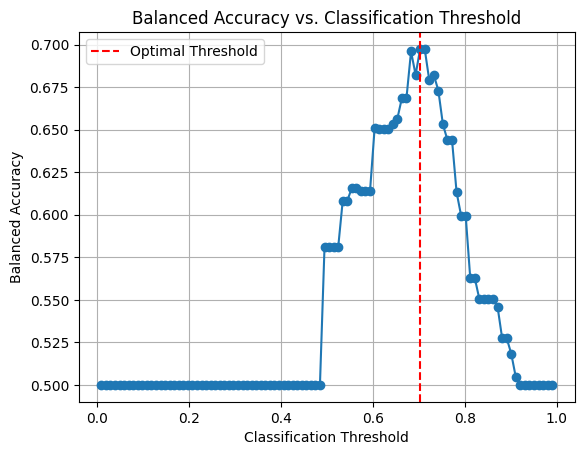

In [38]:
plt.plot(class_thresh_arr, ba_arr, marker='o', linestyle='-')
plt.title('Balanced Accuracy vs. Classification Threshold')
plt.xlabel('Classification Threshold')
plt.ylabel('Balanced Accuracy')
plt.axvline(x=best_class_thresh, color='r', linestyle='--', label='Optimal Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [42]:
display(Markdown("#### Predictions from original testing data"))
bal_acc_arr_orig = []
disp_imp_arr_orig = []
avg_odds_diff_arr_orig = []

print("Classification threshold used = %.4f" % best_class_thresh)
for thresh in tqdm(class_thresh_arr):

    if thresh == best_class_thresh:
        disp = True
    else:
        disp = False

    fav_inds = dataset_orig_test_pred.scores > thresh
    dataset_orig_test_pred.labels[fav_inds] = dataset_orig_test_pred.favorable_label
    dataset_orig_test_pred.labels[~fav_inds] = dataset_orig_test_pred.unfavorable_label

    metric_test_bef = compute_metrics(dataset_orig_test, dataset_orig_test_pred,
                                      unprivileged_groups, privileged_groups,
                                      disp = disp)

    bal_acc_arr_orig.append(metric_test_bef["Balanced accuracy"])
    avg_odds_diff_arr_orig.append(metric_test_bef["Average odds difference"])
    disp_imp_arr_orig.append(metric_test_bef["Disparate impact"])

#### Predictions from original testing data

Classification threshold used = 0.7029


  0%|          | 0/100 [00:00<?, ?it/s]/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/aif360/metrics/dataset_metric.py:82: RuntimeWarning: invalid value encountered in scalar divide
  return metric_fun(privileged=False) / metric_fun(privileged=True)
100%|██████████| 100/100 [00:00<00:00, 2254.74it/s]

Balanced accuracy = 0.6524
Statistical parity difference = -0.0025
Disparate impact = 0.9948
Average odds difference = 0.0071
Equal opportunity difference = 0.0400
Theil index = 0.3906


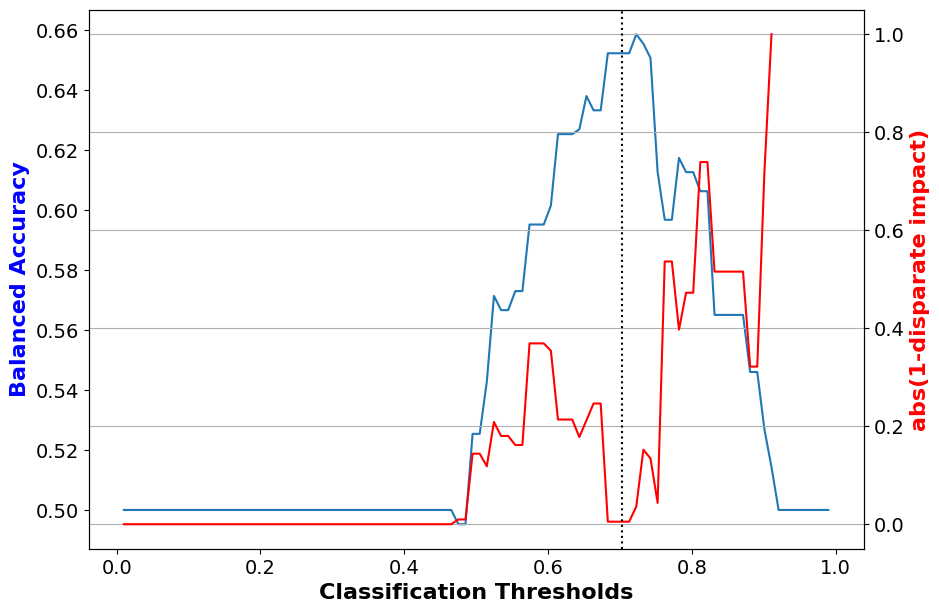

In [43]:
fig, ax1 = plt.subplots(figsize=(10,7))
ax1.plot(class_thresh_arr, bal_acc_arr_orig)
ax1.set_xlabel('Classification Thresholds', fontsize=16, fontweight='bold')
ax1.set_ylabel('Balanced Accuracy', color='b', fontsize=16, fontweight='bold')
ax1.xaxis.set_tick_params(labelsize=14)
ax1.yaxis.set_tick_params(labelsize=14)

ax2 = ax1.twinx()
ax2.plot(class_thresh_arr, np.abs(1.0-np.array(disp_imp_arr_orig)), color='r')
ax2.set_ylabel('abs(1-disparate impact)', color='r', fontsize=16, fontweight='bold')
ax2.axvline(best_class_thresh, color='k', linestyle=':')
ax2.yaxis.set_tick_params(labelsize=14)
ax2.grid(True)

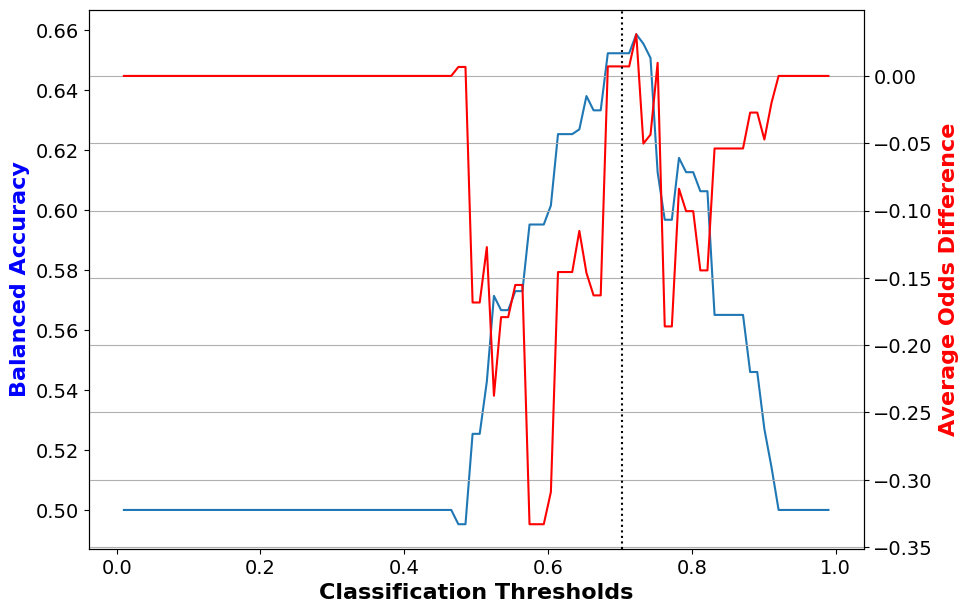

In [44]:
# Create a figure and axis for the plot
fig, ax1 = plt.subplots(figsize=(10,7))

# Plot balanced accuracy against classification thresholds on the primary axis
ax1.plot(class_thresh_arr, bal_acc_arr_orig)
ax1.set_xlabel('Classification Thresholds', fontsize=16, fontweight='bold')
ax1.set_ylabel('Balanced Accuracy', color='b', fontsize=16, fontweight='bold')
ax1.xaxis.set_tick_params(labelsize=14)
ax1.yaxis.set_tick_params(labelsize=14)

# Create a secondary axis to plot average odds difference
ax2 = ax1.twinx()
ax2.plot(class_thresh_arr, avg_odds_diff_arr_orig, color='r')
ax2.set_ylabel('Average Odds Difference', color='r', fontsize=16, fontweight='bold')
ax2.axvline(best_class_thresh, color='k', linestyle=':')
ax2.yaxis.set_tick_params(labelsize=14)
ax2.grid(True)

plt.show()

In [45]:
# Train classifier on transformed data
scale_transf = StandardScaler()
X_train = scale_transf.fit_transform(dataset_transf_train.features)
y_train = dataset_transf_train.labels.ravel()

lmod = LogisticRegression()
lmod.fit(X_train, y_train,
        sample_weight=dataset_transf_train.instance_weights)
y_train_pred = lmod.predict(X_train)

In [46]:
# Prepare transformed test dataset for evaluation
dataset_transf_test_pred = dataset_orig_test.copy(deepcopy=True)  # Create a deep copy of the original test dataset

# Standardize the features of the copied test dataset using the same scaler as used during training
X_test = scale_transf.fit_transform(dataset_transf_test_pred.features)

# Extract labels from the copied test dataset
y_test = dataset_transf_test_pred.labels

# Predict scores (probabilities) for the positive class using the logistic regression model trained on the transformed training data
dataset_transf_test_pred.scores = lmod.predict_proba(X_test)[:, pos_ind].reshape(-1, 1)

In [47]:
display(Markdown("#### Predictions from transformed testing data"))
bal_acc_arr_transf = []
disp_imp_arr_transf = []
avg_odds_diff_arr_transf = []

print("Classification threshold used = %.4f" % best_class_thresh)
for thresh in tqdm(class_thresh_arr):

    if thresh == best_class_thresh:
        disp = True
    else:
        disp = False

    fav_inds = dataset_transf_test_pred.scores > thresh
    dataset_transf_test_pred.labels[fav_inds] = dataset_transf_test_pred.favorable_label
    dataset_transf_test_pred.labels[~fav_inds] = dataset_transf_test_pred.unfavorable_label

    metric_test_aft = compute_metrics(dataset_orig_test, dataset_transf_test_pred,
                                      unprivileged_groups, privileged_groups,
                                      disp = disp)

    bal_acc_arr_transf.append(metric_test_aft["Balanced accuracy"])
    avg_odds_diff_arr_transf.append(metric_test_aft["Average odds difference"])
    disp_imp_arr_transf.append(metric_test_aft["Disparate impact"])

#### Predictions from transformed testing data

Classification threshold used = 0.7029


  0%|          | 0/100 [00:00<?, ?it/s]/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/aif360/metrics/dataset_metric.py:82: RuntimeWarning: divide by zero encountered in scalar divide
  return metric_fun(privileged=False) / metric_fun(privileged=True)
/Users/harshkyada/Desktop/ToU EEA Challenge/venv/lib/python3.13/site-packages/aif360/metrics/dataset_metric.py:82: RuntimeWarning: invalid value encountered in scalar divide
  return metric_fun(privileged=False) / metric_fun(privileged=True)
100%|██████████| 100/100 [00:00<00:00, 1700.65it/s]

Balanced accuracy = 0.6476
Statistical parity difference = 0.0071
Disparate impact = 1.0151
Average odds difference = 0.0137
Equal opportunity difference = 0.0533
Theil index = 0.4005


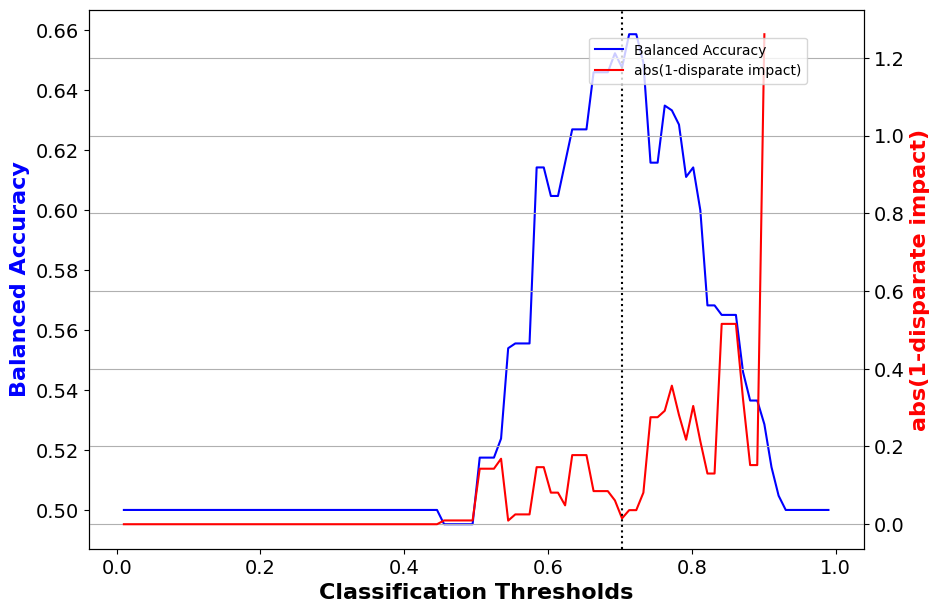

In [48]:
fig, ax1 = plt.subplots(figsize=(10,7))

# Plot balanced accuracy
ax1.plot(class_thresh_arr, bal_acc_arr_transf, label='Balanced Accuracy', color='b')
ax1.set_xlabel('Classification Thresholds', fontsize=16, fontweight='bold')
ax1.set_ylabel('Balanced Accuracy', color='b', fontsize=16, fontweight='bold')
ax1.xaxis.set_tick_params(labelsize=14)
ax1.yaxis.set_tick_params(labelsize=14)

# Create a twin Axes sharing the same x-axis
ax2 = ax1.twinx()

# Plot absolute difference of 1 and disparate impact
ax2.plot(class_thresh_arr, np.abs(1.0 - np.array(disp_imp_arr_transf)), label='abs(1-disparate impact)', color='r')
ax2.set_ylabel('abs(1-disparate impact)', color='r', fontsize=16, fontweight='bold')
ax2.axvline(best_class_thresh, color='k', linestyle=':')  # Mark the best classification threshold
ax2.yaxis.set_tick_params(labelsize=14)
ax2.grid(True)

# Show legend
fig.legend(loc="upper right", bbox_to_anchor=(0.85, 0.85))

plt.show()

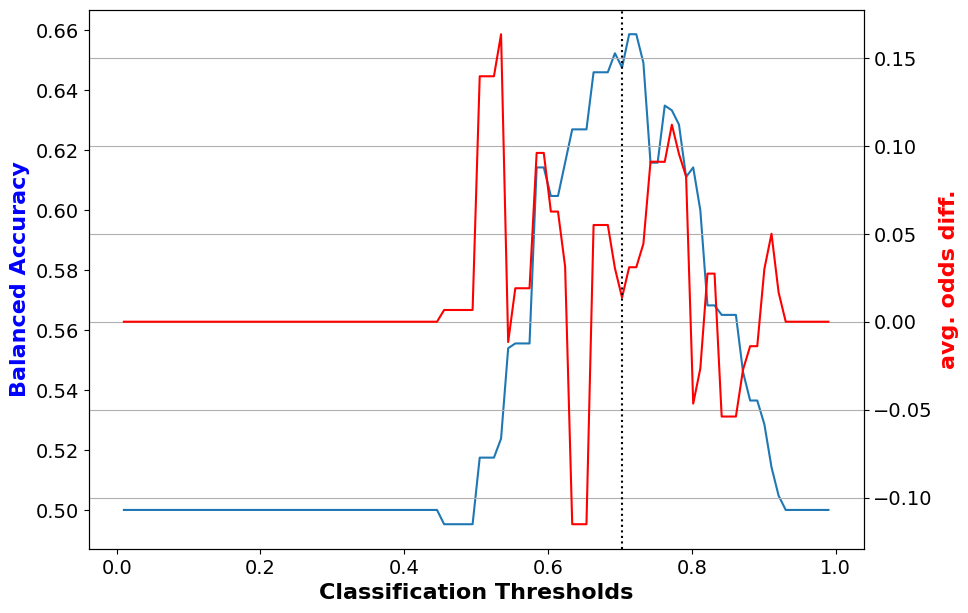

In [49]:
fig, ax1 = plt.subplots(figsize=(10,7))
ax1.plot(class_thresh_arr, bal_acc_arr_transf)
ax1.set_xlabel('Classification Thresholds', fontsize=16, fontweight='bold')
ax1.set_ylabel('Balanced Accuracy', color='b', fontsize=16, fontweight='bold')
ax1.xaxis.set_tick_params(labelsize=14)
ax1.yaxis.set_tick_params(labelsize=14)

ax2 = ax1.twinx()
ax2.plot(class_thresh_arr, avg_odds_diff_arr_transf, color='r')
ax2.set_ylabel('avg. odds diff.', color='r', fontsize=16, fontweight='bold')
ax2.axvline(best_class_thresh, color='k', linestyle=':')
ax2.yaxis.set_tick_params(labelsize=14)
ax2.grid(True)